# Data Preprocessing: Retail Dirty Transactions Dataset
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset transaksi ritel kotor (*Retail Dirty Transactions*).

* **Dataset Asal:** `retail_transactions_5500_dirty.csv` (5.500 transaksi ritel)
* **Karakteristik Data:** 5.500 baris transaksi dengan 3 atribut (`InvoiceNo`, `Description`, `Quantity`), memuat transaksi batal (*cancellation* 'C'), retur kuantitas negatif, missing value, dan data duplikat.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Transaksi Unik (Invoice)
  4. Analisis Frekuensi Produk Terpopuler
  5. Deteksi Data Pencilan (*Outlier*) pada Ukuran Keranjang Belanja menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 2. Membaca Dataset
Memuat file CSV dataset transaksi ritel ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('retail_transactions_5500_dirty.csv')


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi belanja ritel.


In [3]:
df.head()


,InvoiceNo,Description,Quantity
0,INV1603,Biscuits,2
1,INV1119,Wheat Flour,3
2,INV1652,Wheat Flour,5
3,INV1467,Sugar,2
4,CINV1357,Detergent,4


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi belanja ritel.


In [4]:
df.tail()


,InvoiceNo,Description,Quantity
5495,INV1526,Salt,4
5496,INV1088,Detergent,5
5497,INV1377,Bread,5
5498,CINV1068,Chocolate,3
5499,INV1406,Toothpaste,1


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 5500


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom atribut pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 3


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   InvoiceNo    5500 non-null   str  
 1   Description  5221 non-null   str  
 2   Quantity     5500 non-null   int64
dtypes: int64(1), str(2)
memory usage: 129.0 KB


### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom transaksi ritel.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
InvoiceNo,0
Description,279
Quantity,0


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 279


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 1.69%


### 11. Visualisasi Heatmap Missing Value
Menampilkan peta sebaran nilai kosong pada seluruh baris transaksi.


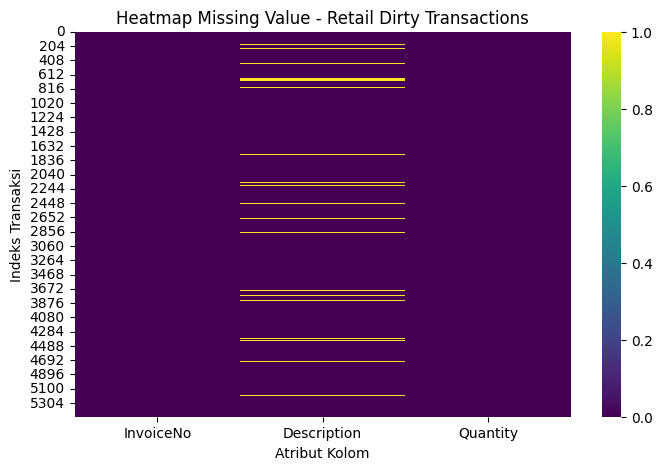

In [11]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value - Retail Dirty Transactions')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


### 12. Cek Jumlah Duplikat Data
Memeriksa apakah terdapat baris duplikat penuh pada data transaksi belanja.


In [12]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah Baris Duplikat:", jumlah_duplikat)


Jumlah Baris Duplikat: 114


### 13. Cek Jumlah Transaksi Unik (Invoice)
Menghitung total nomor faktur / struk transaksi unik (InvoiceNo).


In [13]:
print("Jumlah Transaksi Unik (InvoiceNo):", df['InvoiceNo'].nunique())


Jumlah Transaksi Unik (InvoiceNo): 1201


### 14. Frekuensi Produk Terpopuler
Menghitung frekuensi kemunculan 10 produk teratas di seluruh transaksi ritel.


In [14]:
top_produk = df['Description'].value_counts().to_frame(name='Jumlah Pembelian')
print("Frekuensi 10 Produk Terpopuler:")
display(top_produk.head(10))


Frekuensi 10 Produk Terpopuler:


,Jumlah Pembelian
Description,
Cooking Oil,290
Sugar,286
Shampoo,281
Detergent,278
Wheat Flour,275
Jam,275
Toothpaste,273
Bread,269
Spices,268


### 15. Hitung Ukuran Keranjang Belanja per Invoice
Menghitung banyaknya item produk yang dibeli pada setiap nomor faktur belanja (InvoiceNo).


In [15]:
item_per_invoice = df.groupby('InvoiceNo')['Description'].count()
item_per_invoice.name = 'Ukuran_Keranjang' 


### 16. Statistik Deskriptif Ukuran Keranjang Belanja
Melihat nilai rata-rata, standar deviasi, nilai minimum, dan maksimum ukuran keranjang belanja.


In [16]:
item_per_invoice.describe().to_frame(name='Statistik Deskriptif')


,Statistik Deskriptif
count,1201.000000
mean,4.347211
std,2.918078
min,0.000000
25%,1.000000
50%,4.000000
75%,7.000000
max,16.000000


### 17. Visualisasi Boxplot Ukuran Keranjang Belanja
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran dan deteksi pencilan belanja.


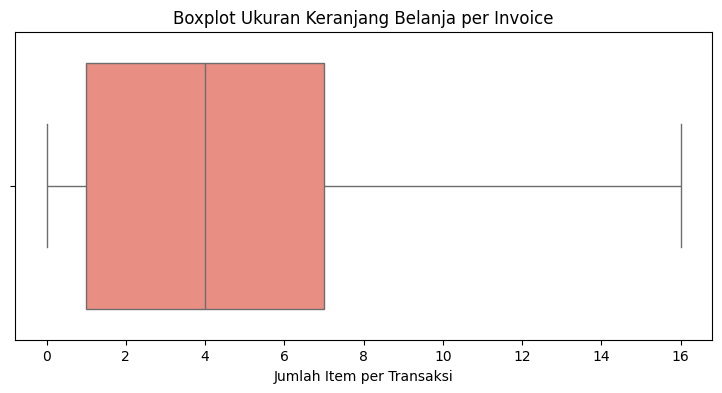

In [17]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=item_per_invoice, color='salmon')
plt.title('Boxplot Ukuran Keranjang Belanja per Invoice')
plt.xlabel('Jumlah Item per Transaksi')
plt.show()


### 18. Perhitungan Kuartil (Q1, Q3) dan IQR
Menghitung batas kuartil bawah (25%), kuartil atas (75%), dan rentang antarkuartil (IQR).


In [18]:
Q1 = item_per_invoice.quantile(0.25)
Q3 = item_per_invoice.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 (Kuartil Bawah) : {Q1}")
print(f"Q3 (Kuartil Atas)  : {Q3}")
print(f"IQR               : {IQR}")


Q1 (Kuartil Bawah) : 1.0
Q3 (Kuartil Atas)  : 7.0
IQR               : 6.0


### 19. Perhitungan Batas Atas Outlier
Menghitung ambang batas atas deteksi outlier menggunakan rumus Q3 + (1.5 * IQR).


In [19]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas)


Batas Atas Outlier: 16.0


### 20. Jumlah Transaksi Terdeteksi Outlier
Menghitung total transaksi belanja yang melampaui batas atas IQR.


In [20]:
outliers = item_per_invoice[item_per_invoice > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))


Jumlah Transaksi Outlier: 0


### 21. Daftar 10 Transaksi dengan Keranjang Belanja Terbesar
Menampilkan 10 transaksi teratas dengan volume pembelian item tertinggi.


In [21]:
item_per_invoice.sort_values(ascending=False).head(10).to_frame(name='Jumlah Item Belanja')


,Jumlah Item Belanja
InvoiceNo,
INV1467,16
INV1109,13
INV1191,12
INV1123,12
INV1353,12
INV1370,12
INV1261,12
INV1342,12
INV1382,12
